In [1]:
#!pip install scikit-fuzzy

In [64]:
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import numpy as np


###  **Variables de entrada (Antecedentes)**

#### Cantidad de Vehículos (QV): Evalúa el volumen de tráfico (bajo, medio, alto).
#### Tiempo de Espera (TE): El tiempo que los vehículos han estado esperando (corto, medio, largo).
#### Hora del Día (HD): Determina si es hora pico o no (no pico, pico, pico extremo).
#### Estado del Semáforo (ES): Tiempo actual en el ciclo del semáforo (rojo, amarillo, verde).
#### Condiciones Meteorológicas (CM): Pueden afectar significativamente la velocidad y la seguridad del tráfico (claro, lluvioso, nevado).
#### Día de la Semana (DS): El flujo del tráfico puede variar según sea un día laboral o fin de semana (laboral, fin de semana).
#### Eventos Especiales (EE): Eventos que pueden causar un aumento atípico en el tráfico (sin eventos, eventos locales, eventos mayores).

In [65]:
QV = ctrl.Antecedent(np.arange(0, 11, 1), 'Cantidad de vehiculos')
TE = ctrl.Antecedent(np.arange(0, 11, 1), 'Tiempo de espera')
HD = ctrl.Antecedent(np.arange(0, 11, 1), 'Hora del dia')
CM = ctrl.Antecedent(np.arange(0, 11, 1), 'Condiciones meteorologicas')

### **Variables de salida (Consecuentes)**

#### Tiempo de semaforo (TS)

In [66]:
TS = ctrl.Consequent(np.arange(0, 61, 1), 'Tiempo de semaforo')

### **Conjuntos difusos (funciones de membresia)**

In [67]:
# Ccantidad de vehiculo
QV['bajo'] = fuzz.trimf(QV.universe, [0, 0, 3])
QV['medio'] = fuzz.trimf(QV.universe, [2, 5, 7])
QV['alto'] = fuzz.trimf(QV.universe, [6, 10, 10])


f:\fusion_datos\codigo_taller2\fis_env\lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


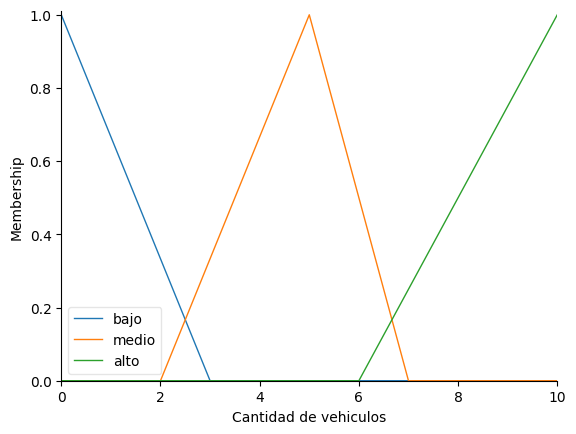

In [48]:
QV.view()

In [68]:
# Tiempo de espera
TE['corto'] = fuzz.trimf(TE.universe, [0, 0, 3])
TE['medio'] = fuzz.trimf(TE.universe, [2, 5, 7])
TE['largo'] = fuzz.trimf(TE.universe, [6, 10, 10])

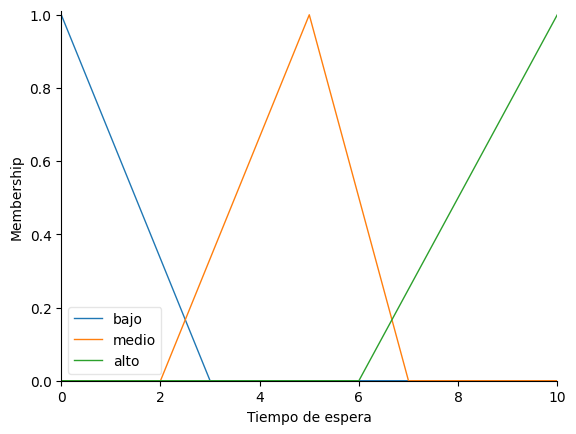

In [18]:
TE.view()

In [69]:
# Hora del dia
HD['no pico'] = fuzz.trimf(HD.universe, [0, 0, 3])
HD['pico'] = fuzz.trimf(HD.universe, [2, 5, 7])
HD['pico extremo'] = fuzz.trimf(HD.universe, [6, 10, 10])

f:\fusion_datos\codigo_taller2\fis_env\lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


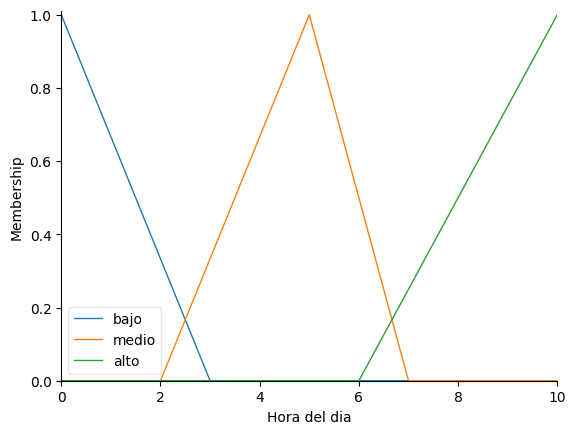

In [20]:
HD.view()

In [103]:
# Condicionres meteorologicas

CM['despejado'] = fuzz.trimf(CM.universe, [0, 0, 3])
CM['nublado'] = fuzz.trimf(CM.universe, [2, 5, 8])
CM['lluvioso'] = fuzz.trimf(CM.universe, [7, 10, 10])

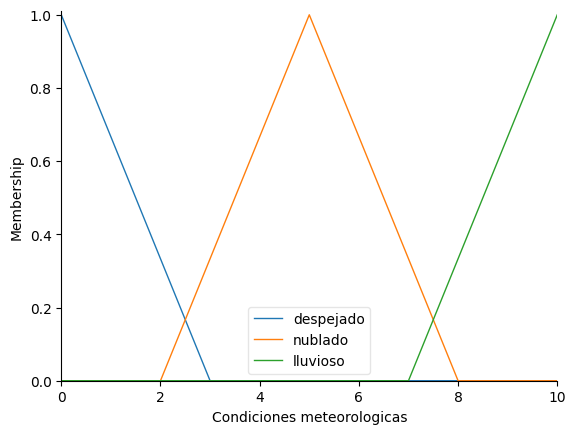

In [104]:
CM.view()

In [72]:
# Escala de tiempo real en segundos para las funciones de membresía de Tiempo de Semáforo 
TS['mas corto'] = fuzz.trimf(TS.universe, [0, 0, 20])  
TS['estandar'] = fuzz.trimf(TS.universe, [15, 30, 45]) 
TS['mas largo'] = fuzz.trimf(TS.universe, [40, 60, 60])

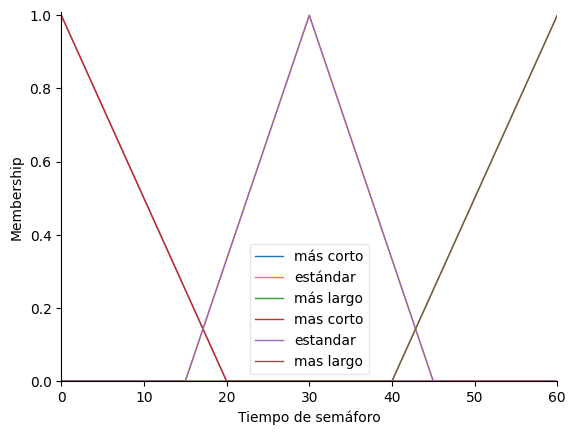

In [54]:
TS.view()

## Crear reglas

In [107]:
rules = []
# Generando todas las combinaciones posibles para 4 variables con 3 estados cada una
for qv_level in ['bajo', 'medio', 'alto']:
    for te_level in ['corto', 'medio', 'largo']:
        for hd_level in ['no pico', 'pico', 'pico extremo']:
            for cm_level in ['despejado', 'nublado', 'lluvioso']:
               if qv_level == 'alto' or te_level == 'largo' or hd_level == 'pico extremo':
                    ts_output = 'mas largo'
               elif cm_level == 'lluvioso' and (qv_level == 'medio' or hd_level == 'pico'):
                    ts_output = 'mas largo'  # Extender tiempo en lluvia para mayor seguridad
               elif qv_level == 'bajo' and te_level == 'corto' and hd_level != 'pico extremo' and cm_level == 'despejado':
                    ts_output = 'mas corto'  # Reducir tiempo si hay pocos vehículos y condiciones son buenas
               else:
                    ts_output = 'estandar'  
                
                # Crear y añadir la regla
               rule = ctrl.Rule(QV[qv_level] & TE[te_level] & HD[hd_level] & CM[cm_level], TS[ts_output])
               rules.append(rule)


In [108]:
cont=0
for rule in rules:
    cont+=1
    print(rule)
print(cont)

IF ((Cantidad de vehiculos[bajo] AND Tiempo de espera[corto]) AND Hora del dia[no pico]) AND Condiciones meteorologicas[despejado] THEN Tiempo de semaforo[mas corto]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF ((Cantidad de vehiculos[bajo] AND Tiempo de espera[corto]) AND Hora del dia[no pico]) AND Condiciones meteorologicas[nublado] THEN Tiempo de semaforo[estandar]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF ((Cantidad de vehiculos[bajo] AND Tiempo de espera[corto]) AND Hora del dia[no pico]) AND Condiciones meteorologicas[lluvioso] THEN Tiempo de semaforo[estandar]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF ((Cantidad de vehiculos[bajo] AND Tiempo de espera[corto]) AND Hora del dia[pico]) AND Condiciones meteorologicas[despejado] THEN Tiempo de semaforo[mas corto]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF ((Cantidad de vehiculos[bajo] AND Tiempo de espera[corto]) AND Hora del dia[p

In [109]:
# Sistema de control y la simulación
ts_ctrl = ctrl.ControlSystem(rules)
ts_sim = ctrl.ControlSystemSimulation(ts_ctrl)

In [88]:
type(ts_sim)

skfuzzy.control.controlsystem.ControlSystemSimulation

In [119]:
# Asignando algunas entradas para probar el sistema
ts_sim.input['Cantidad de vehiculos'] = 5  
ts_sim.input['Tiempo de espera'] = 2
ts_sim.input['Hora del dia'] = 4
ts_sim.input['Condiciones meteorologicas'] = 10


In [120]:
# Computando el resultado
ts_sim.compute()

El tiempo recomendado para el semáforo es: 51.55555555555556 segundos.


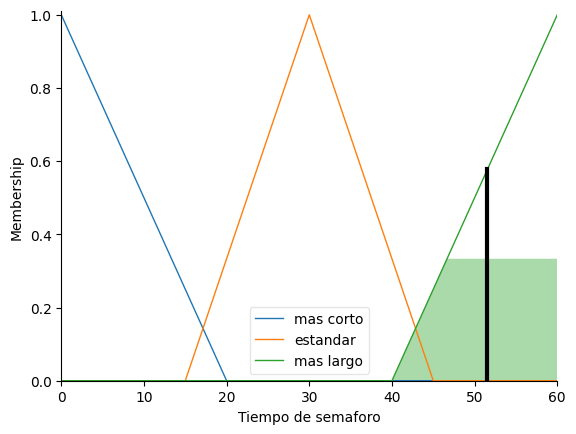

In [124]:
# Imprimiendo el nivel de desempeño resultante
output_ts = ts_sim.output['Tiempo de semaforo']
print(f"El tiempo recomendado para el semáforo es: {output_ts} segundos.")
TS.view(sim=ts_sim)